## **Nama  : Muhammad Fikri Al Maftuh**
## **NIM   : H061241085**

$$ Tugas 3 $$


## Import Modul
Paket utama: `numpy`, `pandas`, dan `matplotlib`. Jalankan sel secara berurutan. Setiap bagian memuat tujuan, konsep minimum, implementasi, visualisasi bila relevan, serta pemeriksaan sederhana. Pemeriksaan kode tidak otomatis membuktikan validitas ilmiah terhadap fenomena nyata.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams["figure.figsize"] = (10, 4.5)
plt.rcParams["axes.grid"] = True
print("Library siap digunakan.")

Library siap digunakan.


## Recipe 1 — Membaca CSV dan ringkasan kualitas data
**Keterkaitan buku:** R-IO-001, *Membaca dan Merangkum Station CSV*; R-QC-001, *Membuat Data Quality Summary*.

**Problem.** Data pengamatan dapat memiliki nilai kosong, timestamp duplikat, atau tipe kolom yang tidak sesuai. Periksa struktur dan kualitas data tanpa mengubah data sumber.

**Minimal theory.** `isna()` menghitung nilai hilang; `duplicated()` menemukan duplikasi; statistik deskriptif memberi gambaran awal, bukan penjelasan penyebab anomali.

In [2]:
dates = pd.date_range("2025-01-01", periods=12, freq="D")
station = pd.DataFrame({
    "time": dates,
    "temperature_C": 27 + 2*np.sin(np.arange(12)*2*np.pi/12) + rng.normal(0, 0.4, 12),
    "rainfall_mm": np.maximum(0, rng.normal(8, 5, 12))
})
station.loc[3, "temperature_C"] = np.nan
station = pd.concat([station, station.iloc[[5]]], ignore_index=True)  # duplikat contoh

print("Ukuran data:", station.shape)
display(station.head())

Ukuran data: (13, 3)


,time,temperature_C,rainfall_mm
0,2025-01-01,27.121887,8.330153
1,2025-01-02,27.584006,13.636206
2,2025-01-03,29.032231,10.337547
3,2025-01-04,NaN,3.703538
4,2025-01-05,27.951637,9.843754


In [3]:
quality_report = pd.DataFrame({
    "dtype": station.dtypes.astype(str),
    "missing_count": station.isna().sum(),
    "missing_percent": (station.isna().mean()*100).round(2),
    "unique_count": station.nunique(dropna=True)
})
duplicate_time_count = int(station["time"].duplicated(keep=False).sum())
display(quality_report)
print(f"Jumlah baris dalam kelompok timestamp duplikat: {duplicate_time_count}")
display(station.describe(include="all").T)

,dtype,missing_count,missing_percent,unique_count
time,datetime64[ns],0,0.00,12
temperature_C,float64,1,7.69,11
rainfall_mm,float64,0,0.00,12


Jumlah baris dalam kelompok timestamp duplikat: 2


,count,mean,min,25%,50%,75%,max,std
time,13,2025-01-06 11:04:36.923076864,2025-01-01 00:00:00,2025-01-04 00:00:00,2025-01-06 00:00:00,2025-01-09 00:00:00,2025-01-12 00:00:00,NaN
temperature_C,12.0,26.785291,24.658782,25.810054,27.086511,27.505348,29.032231,1.259633
rainfall_mm,13.0,8.10893,3.205587,4.595352,7.75037,10.337547,14.112707,3.81641


**Interpretasi:** laporan menandai gejala seperti nilai kosong dan waktu duplikat. Kode tidak otomatis menghapus atau mengisi data; keputusan itu harus mengikuti aturan QA/QC yang dapat dipertanggungjawabkan.

## Recipe 2 — Visualisasi time series
**Keterkaitan buku:** R-VIS-001, *Membuat Time-Series Figure yang Informatif*.

Time series menampilkan perubahan parameter terhadap waktu. Celah pada garis dapat menunjukkan nilai yang hilang; jangan menyamarkannya sebagai observasi valid.

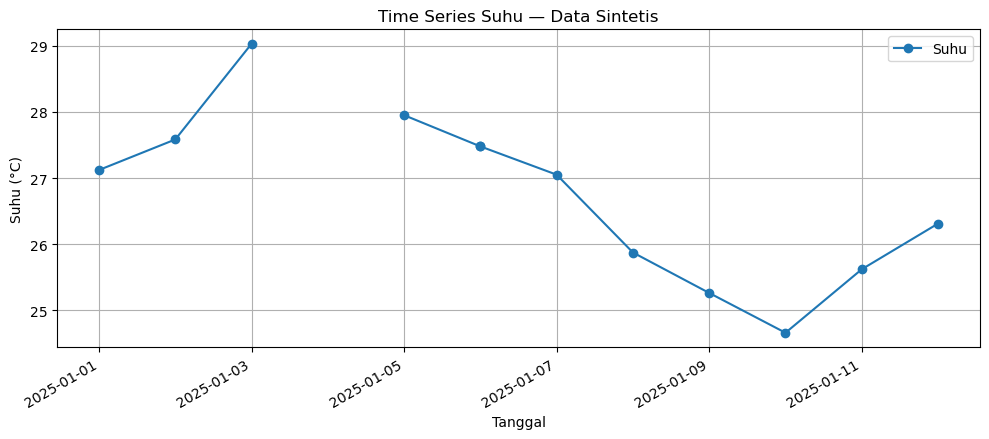

In [4]:
valid = station.sort_values("time")
fig, ax = plt.subplots()
ax.plot(valid["time"], valid["temperature_C"], marker="o", label="Suhu")
ax.set_title("Time Series Suhu — Data Sintetis")
ax.set_xlabel("Tanggal")
ax.set_ylabel("Suhu (°C)")
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## Recipe 3 — Ringkasan musiman / bulanan
**Keterkaitan buku:** R-ANA-001, *Exploratory Seasonal Summary*.

Pengelompokan bulanan menghasilkan ringkasan eksploratif. Untuk data nyata, pastikan cakupan waktu, zona waktu, nilai hilang, dan metode agregasi sesuai dengan pertanyaan penelitian.

In [5]:
daily_dates = pd.date_range("2024-01-01", "2025-12-31", freq="D")
day_of_year = daily_dates.dayofyear.to_numpy()
seasonal_temp = 26 + 3*np.sin(2*np.pi*(day_of_year-30)/365.25) + rng.normal(0, 1, len(daily_dates))
daily = pd.DataFrame({"time": daily_dates, "temperature_C": seasonal_temp})
daily["month"] = daily["time"].dt.month
monthly = daily.groupby("month")["temperature_C"].agg(["mean", "std"]).reset_index()
display(monthly)

,month,mean,std
0,1,25.311619,0.973519
1,2,26.673493,0.981669
2,3,28.003971,1.000337
3,4,28.833450,1.113759
4,5,28.775003,1.004661
5,6,28.170560,0.980905
6,7,26.612754,1.154805
7,8,25.156884,1.115896
8,9,23.841621,1.038430
9,10,23.215945,1.046358


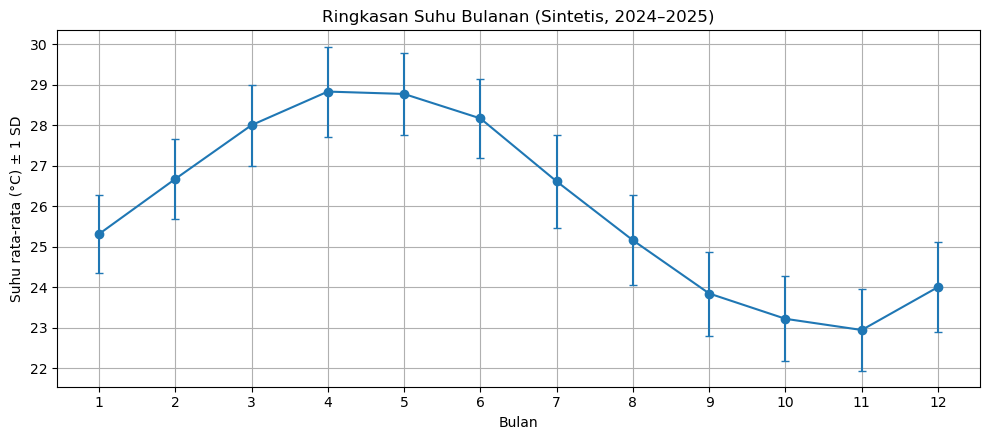

In [6]:
fig, ax = plt.subplots()
ax.errorbar(monthly["month"], monthly["mean"], yerr=monthly["std"], marker="o", capsize=3)
ax.set_title("Ringkasan Suhu Bulanan (Sintetis, 2024–2025)")
ax.set_xlabel("Bulan")
ax.set_ylabel("Suhu rata-rata (°C) ± 1 SD")
ax.set_xticks(range(1, 13))
plt.tight_layout()
plt.show()

## Recipe 4 — Mengubah formula menjadi fungsi Python
**Keterkaitan buku:** R-CAL-001, *Mengubah Formula Menjadi Python Function*.

Untuk dua titik \((z_1,T_1)\) dan \((z_2,T_2)\), gradien diskret:
\[
G = \frac{T_2-T_1}{z_2-z_1}.
\]
Satuan bergantung pada input, misalnya °C/km bila kedalaman dinyatakan dalam km.

In [7]:
def temperature_gradient(z1, T1, z2, T2):
    # Menghitung gradien temperatur; kedalaman harus berbeda.
    if z2 == z1:
        raise ValueError("z1 dan z2 tidak boleh sama.")
    return (T2 - T1) / (z2 - z1)

gradient = temperature_gradient(0.2, 18.0, 1.2, 43.0)
print(f"Gradien temperatur = {gradient:.2f} °C/km")
assert np.isclose(gradient, 25.0)
print("Pemeriksaan formula lulus.")

Gradien temperatur = 25.00 °C/km
Pemeriksaan formula lulus.


## Recipe 5 — Menghitung anomali terhadap baseline
**Keterkaitan buku:** R-CAL-002, *Menghitung Anomaly terhadap Baseline*.

Anomali sederhana adalah \(A(t)=X(t)-\bar{X}_{baseline}\). Pemilihan baseline memengaruhi hasil sehingga periodenya perlu dilaporkan.

Baseline: 2024-01-01 sampai 2024-03-31
Rata-rata baseline: 26.65 °C


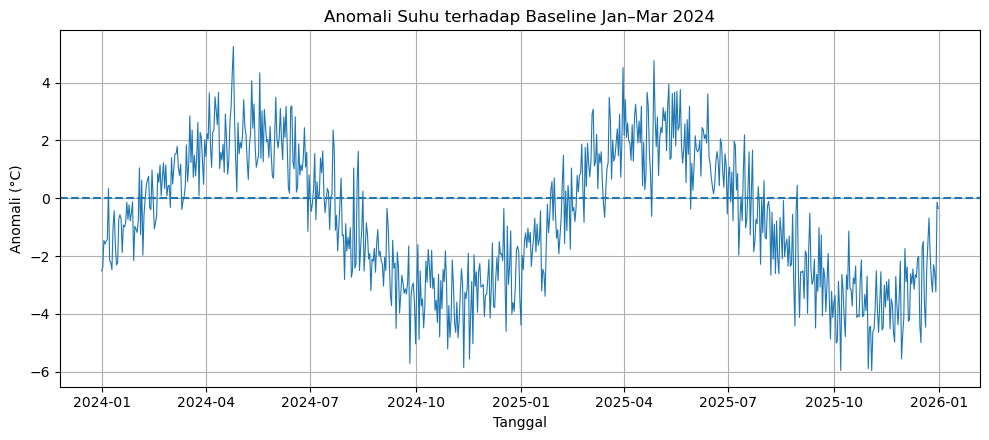

In [8]:
baseline_end = "2024-03-31"
baseline_mask = daily["time"] <= baseline_end
baseline_mean = daily.loc[baseline_mask, "temperature_C"].mean()
daily["anomaly_C"] = daily["temperature_C"] - baseline_mean
print(f"Baseline: 2024-01-01 sampai {baseline_end}")
print(f"Rata-rata baseline: {baseline_mean:.2f} °C")

fig, ax = plt.subplots()
ax.plot(daily["time"], daily["anomaly_C"], linewidth=0.8)
ax.axhline(0, linestyle="--")
ax.set_title("Anomali Suhu terhadap Baseline Jan–Mar 2024")
ax.set_xlabel("Tanggal")
ax.set_ylabel("Anomali (°C)")
plt.tight_layout()
plt.show()

## Recipe 6 — Korelasi dengan lag pada time series
**Keterkaitan buku:** R-CAL-003, *Lag Correlation untuk Time Series*.

Contoh ini mengeksplorasi apakah dua deret waktu berkorelasi ketika salah satunya digeser. Definisi tanda lag: `lag > 0` membandingkan `x(t)` dengan `y(t+lag)`. Korelasi lag bukan bukti sebab-akibat.

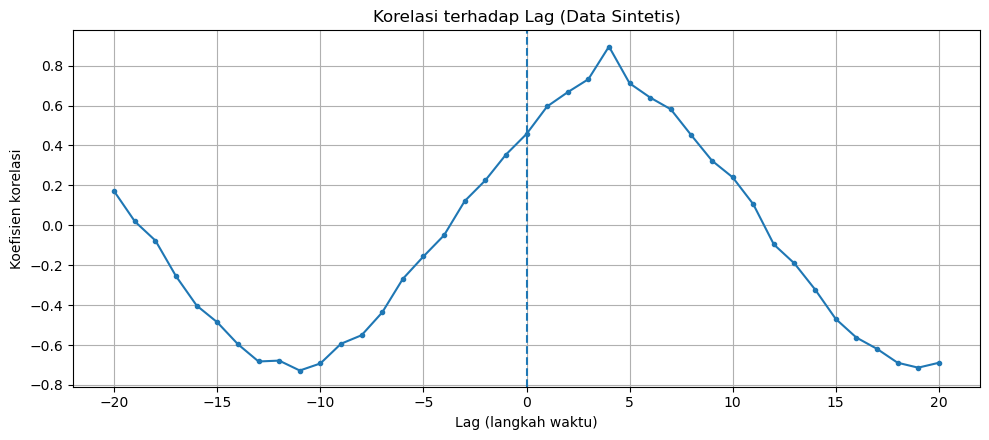

Lag dengan korelasi maksimum: 4


In [9]:
n = 180
t = np.arange(n)
x = np.sin(2*np.pi*t/30) + rng.normal(0, 0.35, n)
y = np.roll(x, 4) + rng.normal(0, 0.4, n)

def lag_correlation(x, y, lag):
    if lag > 0:
        xa, ya = x[:-lag], y[lag:]
    elif lag < 0:
        xa, ya = x[-lag:], y[:lag]
    else:
        xa, ya = x, y
    if len(xa) < 3:
        return np.nan
    return np.corrcoef(xa, ya)[0, 1]

lags = np.arange(-20, 21)
corrs = np.array([lag_correlation(x, y, int(lag)) for lag in lags])
fig, ax = plt.subplots()
ax.plot(lags, corrs, marker="o", markersize=3)
ax.axvline(0, linestyle="--")
ax.set_title("Korelasi terhadap Lag (Data Sintetis)")
ax.set_xlabel("Lag (langkah waktu)")
ax.set_ylabel("Koefisien korelasi")
plt.tight_layout()
plt.show()
print("Lag dengan korelasi maksimum:", int(lags[np.nanargmax(corrs)]))

## Recipe 7 — Model difusi panas satu dimensi
**Keterkaitan buku:** R-MOD-001, *Simulasi Difusi Panas Satu Dimensi*.

Persamaan difusi panas:
\[
\frac{\partial T}{\partial t}=\kappa\frac{\partial^2 T}{\partial z^2},
\]
dengan \(\kappa\) difusivitas termal. Untuk skema beda hingga eksplisit 1D, syarat stabilitas standar adalah \(r=\kappa\Delta t/\Delta z^2\leq 1/2\).

Model ini demonstrasi numerik ideal, bukan model lokasi nyata.

Parameter stabilitas r = 0.036


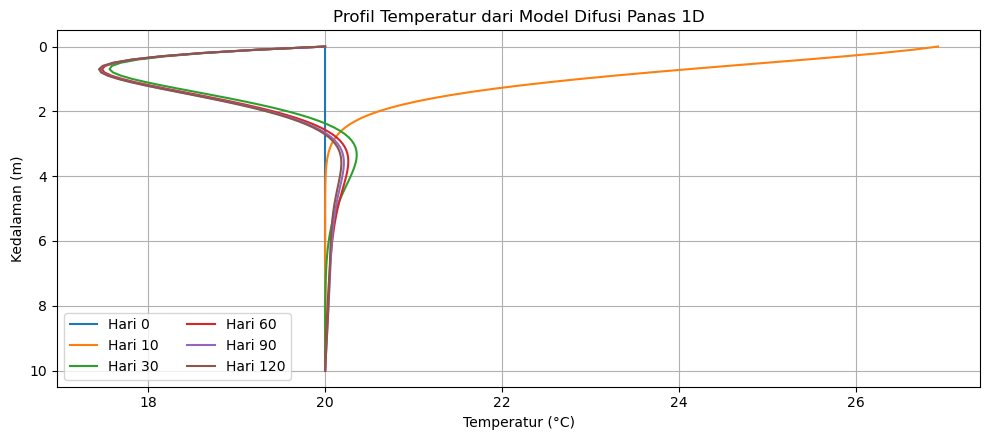

Pemeriksaan dasar lulus. Rentang temperatur akhir: 17.44–20.18 °C


In [10]:
depth_max, dz = 10.0, 0.1
kappa, dt = 1.0e-6, 360.0
days = 120
steps = int(days * 86400 / dt)
z = np.arange(0, depth_max + dz, dz)
r = kappa * dt / dz**2
print(f"Parameter stabilitas r = {r:.3f}")
assert r <= 0.5, "Skema eksplisit tidak memenuhi syarat stabilitas r <= 0.5"

T = np.full_like(z, 20.0)
snapshots = []
snapshot_days = [0, 10, 30, 60, 90, 120]
snapshot_steps = {int(d*86400/dt): d for d in snapshot_days}

for step in range(steps + 1):
    day = step * dt / 86400
    T[0] = 20 + 8*np.sin(2*np.pi*day/30)
    if step in snapshot_steps:
        snapshots.append((snapshot_steps[step], T.copy()))
    if step < steps:
        Tnew = T.copy()
        Tnew[1:-1] = T[1:-1] + r*(T[2:] - 2*T[1:-1] + T[:-2])
        Tnew[-1] = 20.0
        T = Tnew

fig, ax = plt.subplots()
for day, profile in snapshots:
    ax.plot(profile, z, label=f"Hari {day}")
ax.invert_yaxis()
ax.set_title("Profil Temperatur dari Model Difusi Panas 1D")
ax.set_xlabel("Temperatur (°C)")
ax.set_ylabel("Kedalaman (m)")
ax.legend(ncol=2)
plt.tight_layout()
plt.show()
assert np.isfinite(T).all()
assert len(T) == len(z)
print(f"Pemeriksaan dasar lulus. Rentang temperatur akhir: {T.min():.2f}–{T.max():.2f} °C")

## Recipe 8 — Experiment matrix yang dapat direproduksi
**Keterkaitan buku:** R-MOD-003, *Menjalankan Reproducible Experiment Matrix*.

Membandingkan skenario parameter dengan prosedur yang sama. Kondisi awal, kondisi batas, grid, dan durasi dipertahankan; difusivitas termal menjadi parameter yang berubah.

,kappa_m2_s,stability_r,surface_final_C,max_temperature_C,min_temperature_C
0,5.000000e-07,0.015,19.996364,20.222188,18.480252
1,1.000000e-06,0.030,19.996364,20.213317,18.477054
2,1.500000e-06,0.045,19.996364,20.138268,18.475503


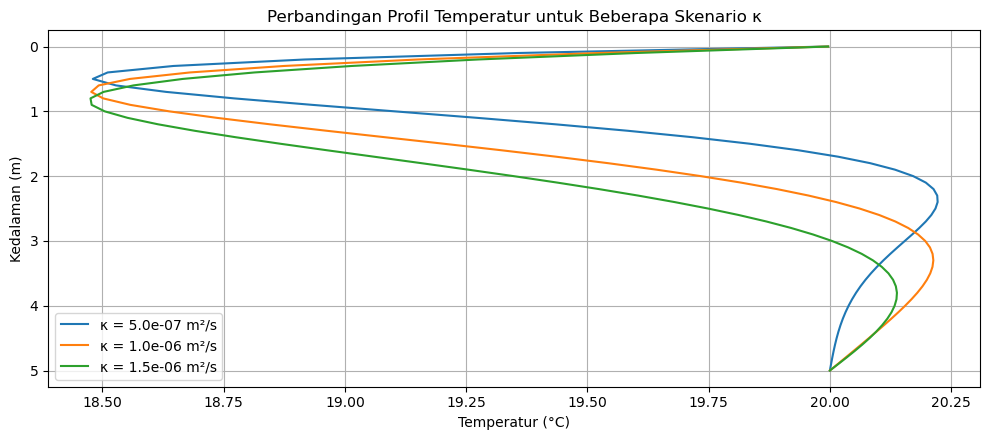

In [11]:
def run_heat_model(kappa_value, days=30, depth_max=5.0, dz=0.1, dt=300.0):
    z_local = np.arange(0, depth_max + dz, dz)
    r_local = kappa_value * dt / dz**2
    if r_local > 0.5:
        raise ValueError(f"Parameter tidak stabil: r={r_local:.3f}")
    temp = np.full_like(z_local, 20.0)
    nsteps = int(days*86400/dt)
    for step in range(nsteps):
        day = step*dt/86400
        temp[0] = 20 + 5*np.sin(2*np.pi*day/30)
        temp_new = temp.copy()
        temp_new[1:-1] = temp[1:-1] + r_local*(temp[2:] - 2*temp[1:-1] + temp[:-2])
        temp_new[-1] = 20.0
        temp = temp_new
    return z_local, temp, r_local

results, profiles = [], {}
for k in [0.5e-6, 1.0e-6, 1.5e-6]:
    zz, tt, rr = run_heat_model(k)
    profiles[k] = (zz, tt)
    results.append({
        "kappa_m2_s": k, "stability_r": rr,
        "surface_final_C": tt[0], "max_temperature_C": tt.max(),
        "min_temperature_C": tt.min()
    })

experiment_summary = pd.DataFrame(results)
display(experiment_summary)

fig, ax = plt.subplots()
for k, (zz, tt) in profiles.items():
    ax.plot(tt, zz, label=f"κ = {k:.1e} m²/s")
ax.invert_yaxis()
ax.set_title("Perbandingan Profil Temperatur untuk Beberapa Skenario κ")
ax.set_xlabel("Temperatur (°C)")
ax.set_ylabel("Kedalaman (m)")
ax.legend()
plt.tight_layout()
plt.show()

## Ringkasan recipe dan batas interpretasi

| Recipe | Implementasi | Output utama |
|---|---|---|
| R-IO-001 / R-QC-001 | Inspeksi data dan kualitas | Missing value, tipe, duplikasi, statistik |
| R-VIS-001 | Visualisasi time series | Grafik suhu terhadap waktu |
| R-ANA-001 | Ringkasan bulanan | Rata-rata dan simpangan baku per bulan |
| R-CAL-001 | Formula menjadi fungsi | Gradien temperatur dan pemeriksaan |
| R-CAL-002 | Anomali baseline | Deret waktu anomali |
| R-CAL-003 | Korelasi lag | Grafik korelasi terhadap lag |
| R-MOD-001 | Difusi panas 1D | Profil temperatur terhadap kedalaman |
| R-MOD-003 | Experiment matrix | Tabel metrik dan perbandingan skenario |

### Catatan akhir
1. Dataset dalam notebook ini sintetis untuk demonstrasi.
2. Plot dan pemeriksaan kode bukan pengganti validasi ilmiah dengan observasi atau solusi referensi.
3. Untuk data nyata, periksa unit, metadata, sumber, rentang waktu, CRS jika spasial, dan aturan penanganan nilai hilang.
4. Ini adalah **pilihan recipe Python lokal**, bukan implementasi seluruh recipe dalam buku. Recipe yang memerlukan API, layanan live, UI, atau integrasi eksternal membutuhkan konfigurasi dan izin terpisah.